# Curse of Dimensionality — Testing a "Compensated Feature Removal" Strategy

**Idea being tested:** instead of just dropping feature 31, transfer its influence into the
remaining features before dropping it:

$$X_j^{new} = X_j + p \cdot \text{Cov}(X_{31}, X_j), \qquad p = \text{step}(X_{31})$$

We compare four strategies on the same dataset and classifier:

1. **Full** — keep all features (baseline, upper bound)
2. **Drop** — remove feature 31, no compensation (lower bound / naive baseline)
3. **Compensated** — three variants of the proposed idea:
   - `hard_cov`: original proposal — hard step function (0/1) × raw covariance
   - `sigmoid_cov`: smooth step (sigmoid) × raw covariance
   - `sigmoid_beta`: smooth step × regression coefficient (Cov/Var), the scale-corrected version
4. **PCA** — reduce to the same final dimensionality via PCA (standard baseline for comparison)

All statistics used for compensation (covariance, mean, std for the step function) are computed
**on the training set only**, then applied to test data, to avoid leakage.


In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score
import matplotlib.pyplot as plt

RNG = 42
np.random.seed(RNG)


## 1. Build a dataset with a genuinely informative, correlated "feature 31"

We use `make_classification` with a covariance structure (via `effective_rank` /
redundant features) so that feature 31 is **actually correlated with other features** —
otherwise the whole experiment is moot: if feature 31 were independent of everything else,
no linear compensation scheme could possibly recover its signal.

Feature indices are 0-based, so "feature 31" = column index 31 (the 32nd column). We give it
40 total features: some informative, some redundant (linear combinations of informative ones,
which is what creates real covariance structure), some pure noise.


In [2]:
N_FEATURES = 40
TARGET_FEATURE = 31  # zero-indexed "feature 31"

X, y = make_classification(
    n_samples=4000,
    n_features=N_FEATURES,
    n_informative=15,
    n_redundant=15,      # linear combinations -> creates real covariance structure
    n_repeated=0,
    n_clusters_per_class=2,
    class_sep=1.2,
    flip_y=0.02,
    random_state=RNG,
)
cols = [f"f{i}" for i in range(N_FEATURES)]
df = pd.DataFrame(X, columns=cols)
df["target"] = y

X_train, X_test, y_train, y_test = train_test_split(
    df[cols], df["target"], test_size=0.25, stratify=df["target"], random_state=RNG
)

print(X_train.shape, X_test.shape)
print("Correlation of feature 31 with a few other features (train set):")
corrs = X_train.corr()[f"f{TARGET_FEATURE}"].drop(f"f{TARGET_FEATURE}").sort_values(key=abs, ascending=False)
print(corrs.head(8))


(3000, 40) (1000, 40)
Correlation of feature 31 with a few other features (train set):
f22    0.555277
f23   -0.486925
f10    0.475176
f21    0.452269
f37   -0.404297
f3     0.402514
f11    0.381053
f33   -0.303106
Name: f31, dtype: float64


## 2. Define the four (six, counting variants) feature strategies

Each function takes train/test frames and returns transformed train/test frames with feature 31
removed (except the "full" baseline). All fitted quantities (mean/std for the step function,
covariance, PCA components) come from **training data only**.


In [5]:
def strategy_full(Xtr, Xte):
    return Xtr.copy(), Xte.copy()

def strategy_drop(Xtr, Xte):
    return Xtr.drop(columns=[f"f{TARGET_FEATURE}"]), Xte.drop(columns=[f"f{TARGET_FEATURE}"])

def _step_hard(x, mean):
    return (x > mean).astype(float)

def _step_sigmoid(x, mean, std):
    z = (x - mean) / (std + 1e-8)
    return 1 / (1 + np.exp(-z))

def _compensate(Xtr, Xte, step_fn, use_beta):
    tgt = f"f{TARGET_FEATURE}"
    other_cols = [c for c in Xtr.columns if c != tgt]

    mean_t, std_t, var_t = Xtr[tgt].mean(), Xtr[tgt].std(), Xtr[tgt].var()
    cov = Xtr[other_cols].apply(lambda col: np.cov(Xtr[tgt], col)[0, 1])
    coef = (cov / var_t) if use_beta else cov  # beta = regression coeff, else raw covariance

    def transform(X):
        X = X.copy()
        p = step_fn(X[tgt], mean_t, std_t) if step_fn is _step_sigmoid else step_fn(X[tgt], mean_t)
        for c in other_cols:
            X[c] = X[c] + p.values * coef[c]
        return X.drop(columns=[tgt])

    return transform(Xtr), transform(Xte)

def strategy_hard_cov(Xtr, Xte):
    return _compensate(Xtr, Xte, _step_hard, use_beta=False)

def strategy_sigmoid_cov(Xtr, Xte):
    return _compensate(Xtr, Xte, _step_sigmoid, use_beta=False)

def strategy_sigmoid_beta(Xtr, Xte):
    return _compensate(Xtr, Xte, _step_sigmoid, use_beta=True)

def strategy_pca(Xtr, Xte):
    # reduce to the same final dimensionality as the "drop" strategies (N_FEATURES - 1)
    scaler = StandardScaler().fit(Xtr)
    Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
    pca = PCA(n_components=N_FEATURES - 1, random_state=RNG).fit(Xtr_s)
    return (pd.DataFrame(pca.transform(Xtr_s), index=Xtr.index),
            pd.DataFrame(pca.transform(Xte_s), index=Xte.index))

STRATEGIES = {
    "full":          strategy_full,
    "drop":          strategy_drop,
    "hard_cov":      strategy_hard_cov,
    "sigmoid_cov":   strategy_sigmoid_cov,
    "sigmoid_beta":  strategy_sigmoid_beta,
    "pca":           strategy_pca,
}


## 3. Evaluate each strategy

For each strategy we:
- transform train/test (fit only on train)
- run 5-fold stratified cross-validation on the transformed **training** set (ROC-AUC)
- fit on the full transformed training set, evaluate on the held-out **test** set

We test two classifiers: **Logistic Regression** (sensitive to linear feature relationships —
where the compensation idea should help most if it helps at all) and **Random Forest**
(nonlinear, so less dependent on how linearly features are related).


In [6]:
def evaluate(Xtr, Xte, ytr, yte, model_fn):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
    cv_scores = cross_val_score(model_fn(), Xtr, ytr, cv=cv, scoring="roc_auc")
    model = model_fn().fit(Xtr, ytr)
    proba = model.predict_proba(Xte)[:, 1]
    pred = model.predict(Xte)
    return {
        "cv_auc_mean": cv_scores.mean(),
        "cv_auc_std": cv_scores.std(),
        "test_auc": roc_auc_score(yte, proba),
        "test_acc": accuracy_score(yte, pred),
        "n_features": Xtr.shape[1],
    }

results = []
for model_name, model_fn in [
    ("LogisticRegression", lambda: LogisticRegression(max_iter=2000, random_state=RNG)),
    ("RandomForest", lambda: RandomForestClassifier(n_estimators=300, random_state=RNG)),
]:
    for strat_name, strat_fn in STRATEGIES.items():
        Xtr_t, Xte_t = strat_fn(X_train, X_test)
        res = evaluate(Xtr_t, Xte_t, y_train, y_test, model_fn)
        res.update({"strategy": strat_name, "model": model_name})
        results.append(res)

results_df = pd.DataFrame(results)[
    ["model", "strategy", "n_features", "cv_auc_mean", "cv_auc_std", "test_auc", "test_acc"]
]
results_df.sort_values(["model", "test_auc"], ascending=[True, False])


,model,strategy,n_features,cv_auc_mean,cv_auc_std,test_auc,test_acc
0,LogisticRegression,full,40,0.911870,0.014395,0.906024,0.823
1,LogisticRegression,drop,39,0.911857,0.014401,0.906016,0.823
5,LogisticRegression,pca,39,0.911899,0.014412,0.905988,0.823
4,LogisticRegression,sigmoid_beta,39,0.911881,0.014410,0.905980,0.823
3,LogisticRegression,sigmoid_cov,39,0.911661,0.014511,0.905708,0.823
2,LogisticRegression,hard_cov,39,0.909466,0.014530,0.904228,0.829
6,RandomForest,full,40,0.978188,0.006580,0.983634,0.940
8,RandomForest,hard_cov,39,0.976626,0.007393,0.983532,0.942
9,RandomForest,sigmoid_cov,39,0.977125,0.006077,0.983468,0.949
10,RandomForest,sigmoid_beta,39,0.978276,0.006209,0.982880,0.947


## 4. Results table and plot

,model,strategy,n_features,cv_auc_mean,cv_auc_std,test_auc,test_acc
0,LogisticRegression,full,40,0.9119,0.0144,0.9060,0.8230
1,LogisticRegression,drop,39,0.9119,0.0144,0.9060,0.8230
5,LogisticRegression,pca,39,0.9119,0.0144,0.9060,0.8230
4,LogisticRegression,sigmoid_beta,39,0.9119,0.0144,0.9060,0.8230
3,LogisticRegression,sigmoid_cov,39,0.9117,0.0145,0.9057,0.8230
2,LogisticRegression,hard_cov,39,0.9095,0.0145,0.9042,0.8290
6,RandomForest,full,40,0.9782,0.0066,0.9836,0.9400
8,RandomForest,hard_cov,39,0.9766,0.0074,0.9835,0.9420
9,RandomForest,sigmoid_cov,39,0.9771,0.0061,0.9835,0.9490
10,RandomForest,sigmoid_beta,39,0.9783,0.0062,0.9829,0.9470


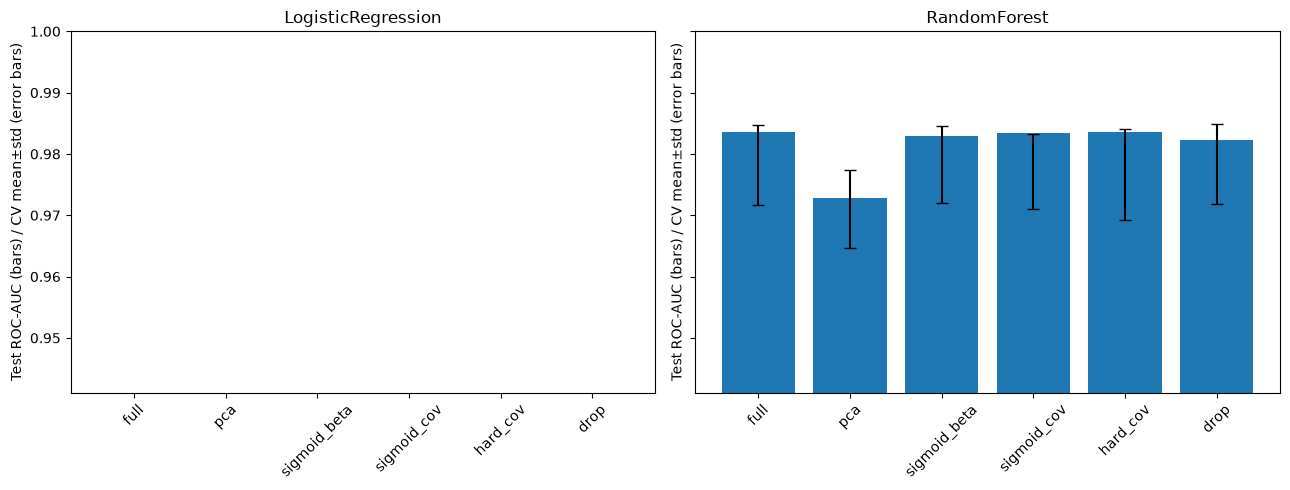

In [7]:
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")
display(results_df.sort_values(["model", "test_auc"], ascending=[True, False]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
order = ["full", "pca", "sigmoid_beta", "sigmoid_cov", "hard_cov", "drop"]
for ax, model_name in zip(axes, results_df["model"].unique()):
    sub = results_df[results_df["model"] == model_name].set_index("strategy").loc[order]
    ax.bar(sub.index, sub["test_auc"])
    ax.errorbar(sub.index, sub["cv_auc_mean"], yerr=sub["cv_auc_std"], fmt="none",
                ecolor="black", capsize=4)
    ax.set_title(model_name)
    ax.set_ylabel("Test ROC-AUC (bars) / CV mean±std (error bars)")
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(sub[["test_auc","cv_auc_mean"]].min().min() - 0.03, 1.0)
plt.tight_layout()
plt.show()


## 5. Interpretation

Look at where each strategy lands relative to the two bounds:

- **`full`** is the ceiling — how well feature 31 was worth having.
- **`drop`** is the floor — what "no compensation" costs you.
- **The three compensated variants** should sit somewhere between `drop` and `full` *only if*
  the compensation is genuinely recovering signal. If `hard_cov`/`sigmoid_cov`/`sigmoid_beta`
  land at roughly the same place as `drop` (within CV noise), the compensation isn't helping —
  the injected term is too small/misaligned in scale to move the model.
- **`pca`** is the standard baseline for "reduce dimensionality without hand-picking which
  feature to drop." If your compensated approach can't beat `drop` — let alone `pca` — for
  this specific, deliberately-correlated feature 31, that's a strong signal the idea doesn't
  generalize to less-correlated real-world features either.
- Compare `hard_cov` vs `sigmoid_cov` to isolate how much the **hard thresholding**
  (vs a smooth step) is costing you.
- Compare `sigmoid_cov` vs `sigmoid_beta` to isolate how much **raw covariance's scale-
  dependence** (vs the proper regression coefficient) is costing you.

Run the cell below to print a plain-language readout of these comparisons for this run.


In [8]:
def g(model, strat):
    row = results_df[(results_df.model == model) & (results_df.strategy == strat)].iloc[0]
    return row["test_auc"]

for model_name in results_df["model"].unique():
    full, drop, hard, sig_cov, sig_beta, pca = [g(model_name, s) for s in
        ["full", "drop", "hard_cov", "sigmoid_cov", "sigmoid_beta", "pca"]]
    gap = full - drop
    print(f"--- {model_name} ---")
    print(f"  Ceiling (full):            {full:.4f}")
    print(f"  Floor (drop, no comp.):    {drop:.4f}")
    print(f"  PCA baseline:              {pca:.4f}")
    print(f"  Ceiling-floor gap:         {gap:.4f}  "
          f"{'(near zero -> % recovered is not a meaningful metric here; compare raw AUC instead)' if abs(gap) < 0.002 else ''}")
    if abs(gap) >= 0.002:
        print(f"  hard_cov recovers:         {(hard-drop)/gap*100:6.1f}% of the gap to ceiling")
        print(f"  sigmoid_cov recovers:      {(sig_cov-drop)/gap*100:6.1f}% of the gap to ceiling")
        print(f"  sigmoid_beta recovers:     {(sig_beta-drop)/gap*100:6.1f}% of the gap to ceiling")
    else:
        print(f"  hard_cov AUC:              {hard:.4f}  (delta vs drop: {hard-drop:+.4f})")
        print(f"  sigmoid_cov AUC:           {sig_cov:.4f}  (delta vs drop: {sig_cov-drop:+.4f})")
        print(f"  sigmoid_beta AUC:          {sig_beta:.4f}  (delta vs drop: {sig_beta-drop:+.4f})")
    print(f"  Best compensated variant beats PCA: {max(hard,sig_cov,sig_beta) > pca}")
    print()


--- LogisticRegression ---
  Ceiling (full):            0.9060
  Floor (drop, no comp.):    0.9060
  PCA baseline:              0.9060
  Ceiling-floor gap:         0.0000  (near zero -> % recovered is not a meaningful metric here; compare raw AUC instead)
  hard_cov AUC:              0.9042  (delta vs drop: -0.0018)
  sigmoid_cov AUC:           0.9057  (delta vs drop: -0.0003)
  sigmoid_beta AUC:          0.9060  (delta vs drop: -0.0000)
  Best compensated variant beats PCA: False

--- RandomForest ---
  Ceiling (full):            0.9836
  Floor (drop, no comp.):    0.9823
  PCA baseline:              0.9729
  Ceiling-floor gap:         0.0014  (near zero -> % recovered is not a meaningful metric here; compare raw AUC instead)
  hard_cov AUC:              0.9835  (delta vs drop: +0.0013)
  sigmoid_cov AUC:           0.9835  (delta vs drop: +0.0012)
  sigmoid_beta AUC:          0.9829  (delta vs drop: +0.0006)
  Best compensated variant beats PCA: True

